## REGRESIÓN

En este fichero se va a realizar la segunda tarea del proyecto. Para esta tarea he utilizado los modelos de regresión lineal sin aplicar regularización y aplicando Lasso y Elastic Net, además, para finalizar, aplico el modelo de RandomForest Regressor para comparar los resultados obtenidos.

In [1]:
# Importamos las librería
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import math
import numpy as np
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, KFold, cross_val_score

## 1. Carga y exploración de los datos

Comenzamos por importar los datos y realizar una exploración. Además, haremos una primera visión de la variable objetivo para entender su distribución antes de entrenar los modelos.

In [2]:
df = pd.read_csv("../rendimiento_estudiantes_limpio.csv")
print(df.columns)

Index(['estado_civil', 'modo_solicitud', 'orden_solicitud', 'curso',
       'asistencia_diurna_vespertina', 'cualificacion_previa',
       'nota_cualificacion_previa', 'cualificacion_madre',
       'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre',
       'nota_admision', 'desplazado', 'necesidades_educativas_especiales',
       'deudor', 'matricula_al_dia', 'genero', 'becado',
       'edad_al_matricularse', 'internacional',
       'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas',
       'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas',
       'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion',
       'asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas',
       'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas',
       'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo',
       'tasa_inflacion', 'pib', 'objetivo'],
      dtype='object')


Para evitar cualquier posibilidad de data leakage elimino todas las variables que tienen que ver con el segundo semestre, es decir, aquellas cuyo nombre comienzan por **asignaturas_2sem_*** pues pueden aportar información sobre el semestre casi equivalente a la nota que se quiere predecir. Además, la variable **objetivo** también la eliminamos pues puede contaminar los datos aportando información de mas.     
La variable que se quiere predecir con estos modelos es: **nota_media_2sem**

In [3]:
# A continuación, comprobamos valores faltantes
nulos=df.isna().sum()
print("Número de variables con valores faltantes: ", (nulos>0).sum())


Número de variables con valores faltantes:  0


Como se puede observar, no hay valores faltantes en ninguna de las variables. 

In [4]:
X = df.drop(columns=["objetivo", 
                     "asignaturas_2sem_convalidadas", 
                     "asignaturas_2sem_matriculadas", 
                     "asignaturas_2sem_evaluadas", 
                     "asignaturas_2sem_aprobadas", 
                     "nota_media_2sem",
                     "asignaturas_2sem_sin_evaluacion"]).copy()
y = df["nota_media_2sem"]

col_cat = X.select_dtypes(include=["object", "category"]).columns.to_list()
col_num = X.select_dtypes(include=["int64", "float64"]).columns.to_list()

print(f"Variables categóricas: {len(col_cat)}")
print(f"Variables numéricas: {len(col_num)}")

Variables categóricas: 16
Variables numéricas: 13


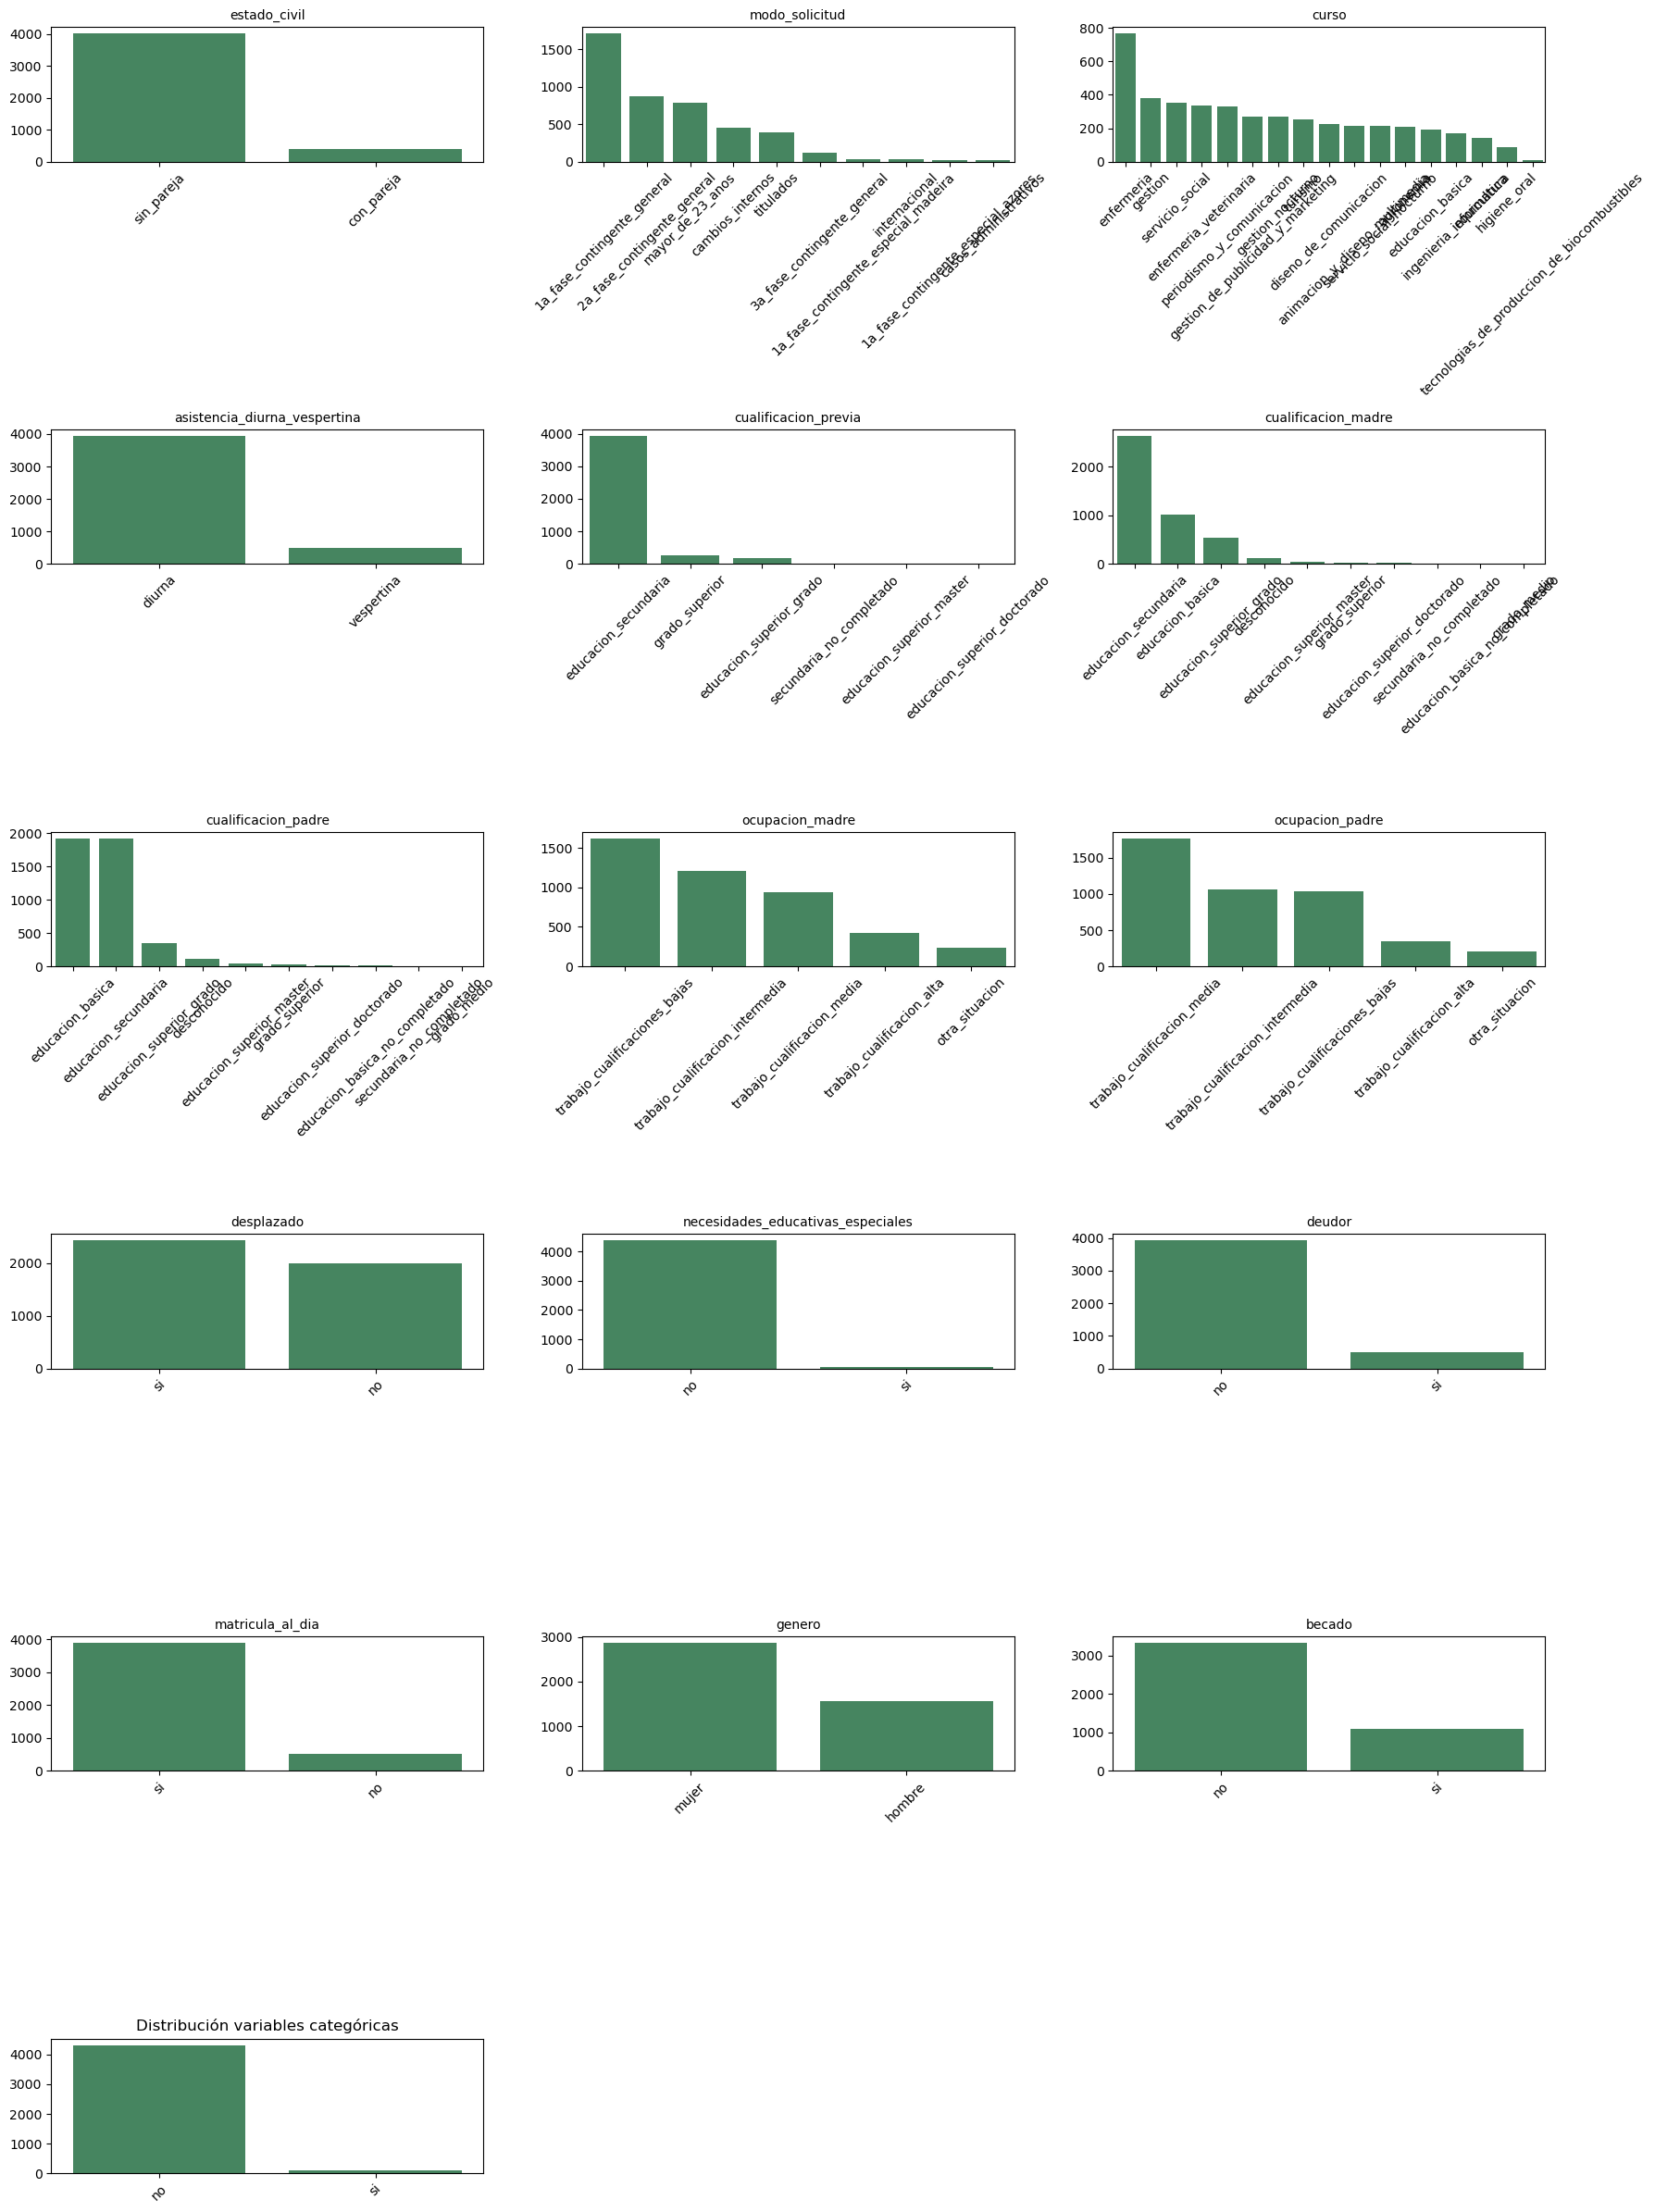

In [5]:
# Mostrar frecuencias de variables categóricas
n_cols = 3  # número de columnas en la cuadrícula
n_rows = math.ceil(len(col_cat) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(col_cat):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=axes[i], color="#3b905e")
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

# borrar ejes vacíos si sobran
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
    
plt.title('Distribución variables categóricas')
plt.tight_layout()
plt.show()

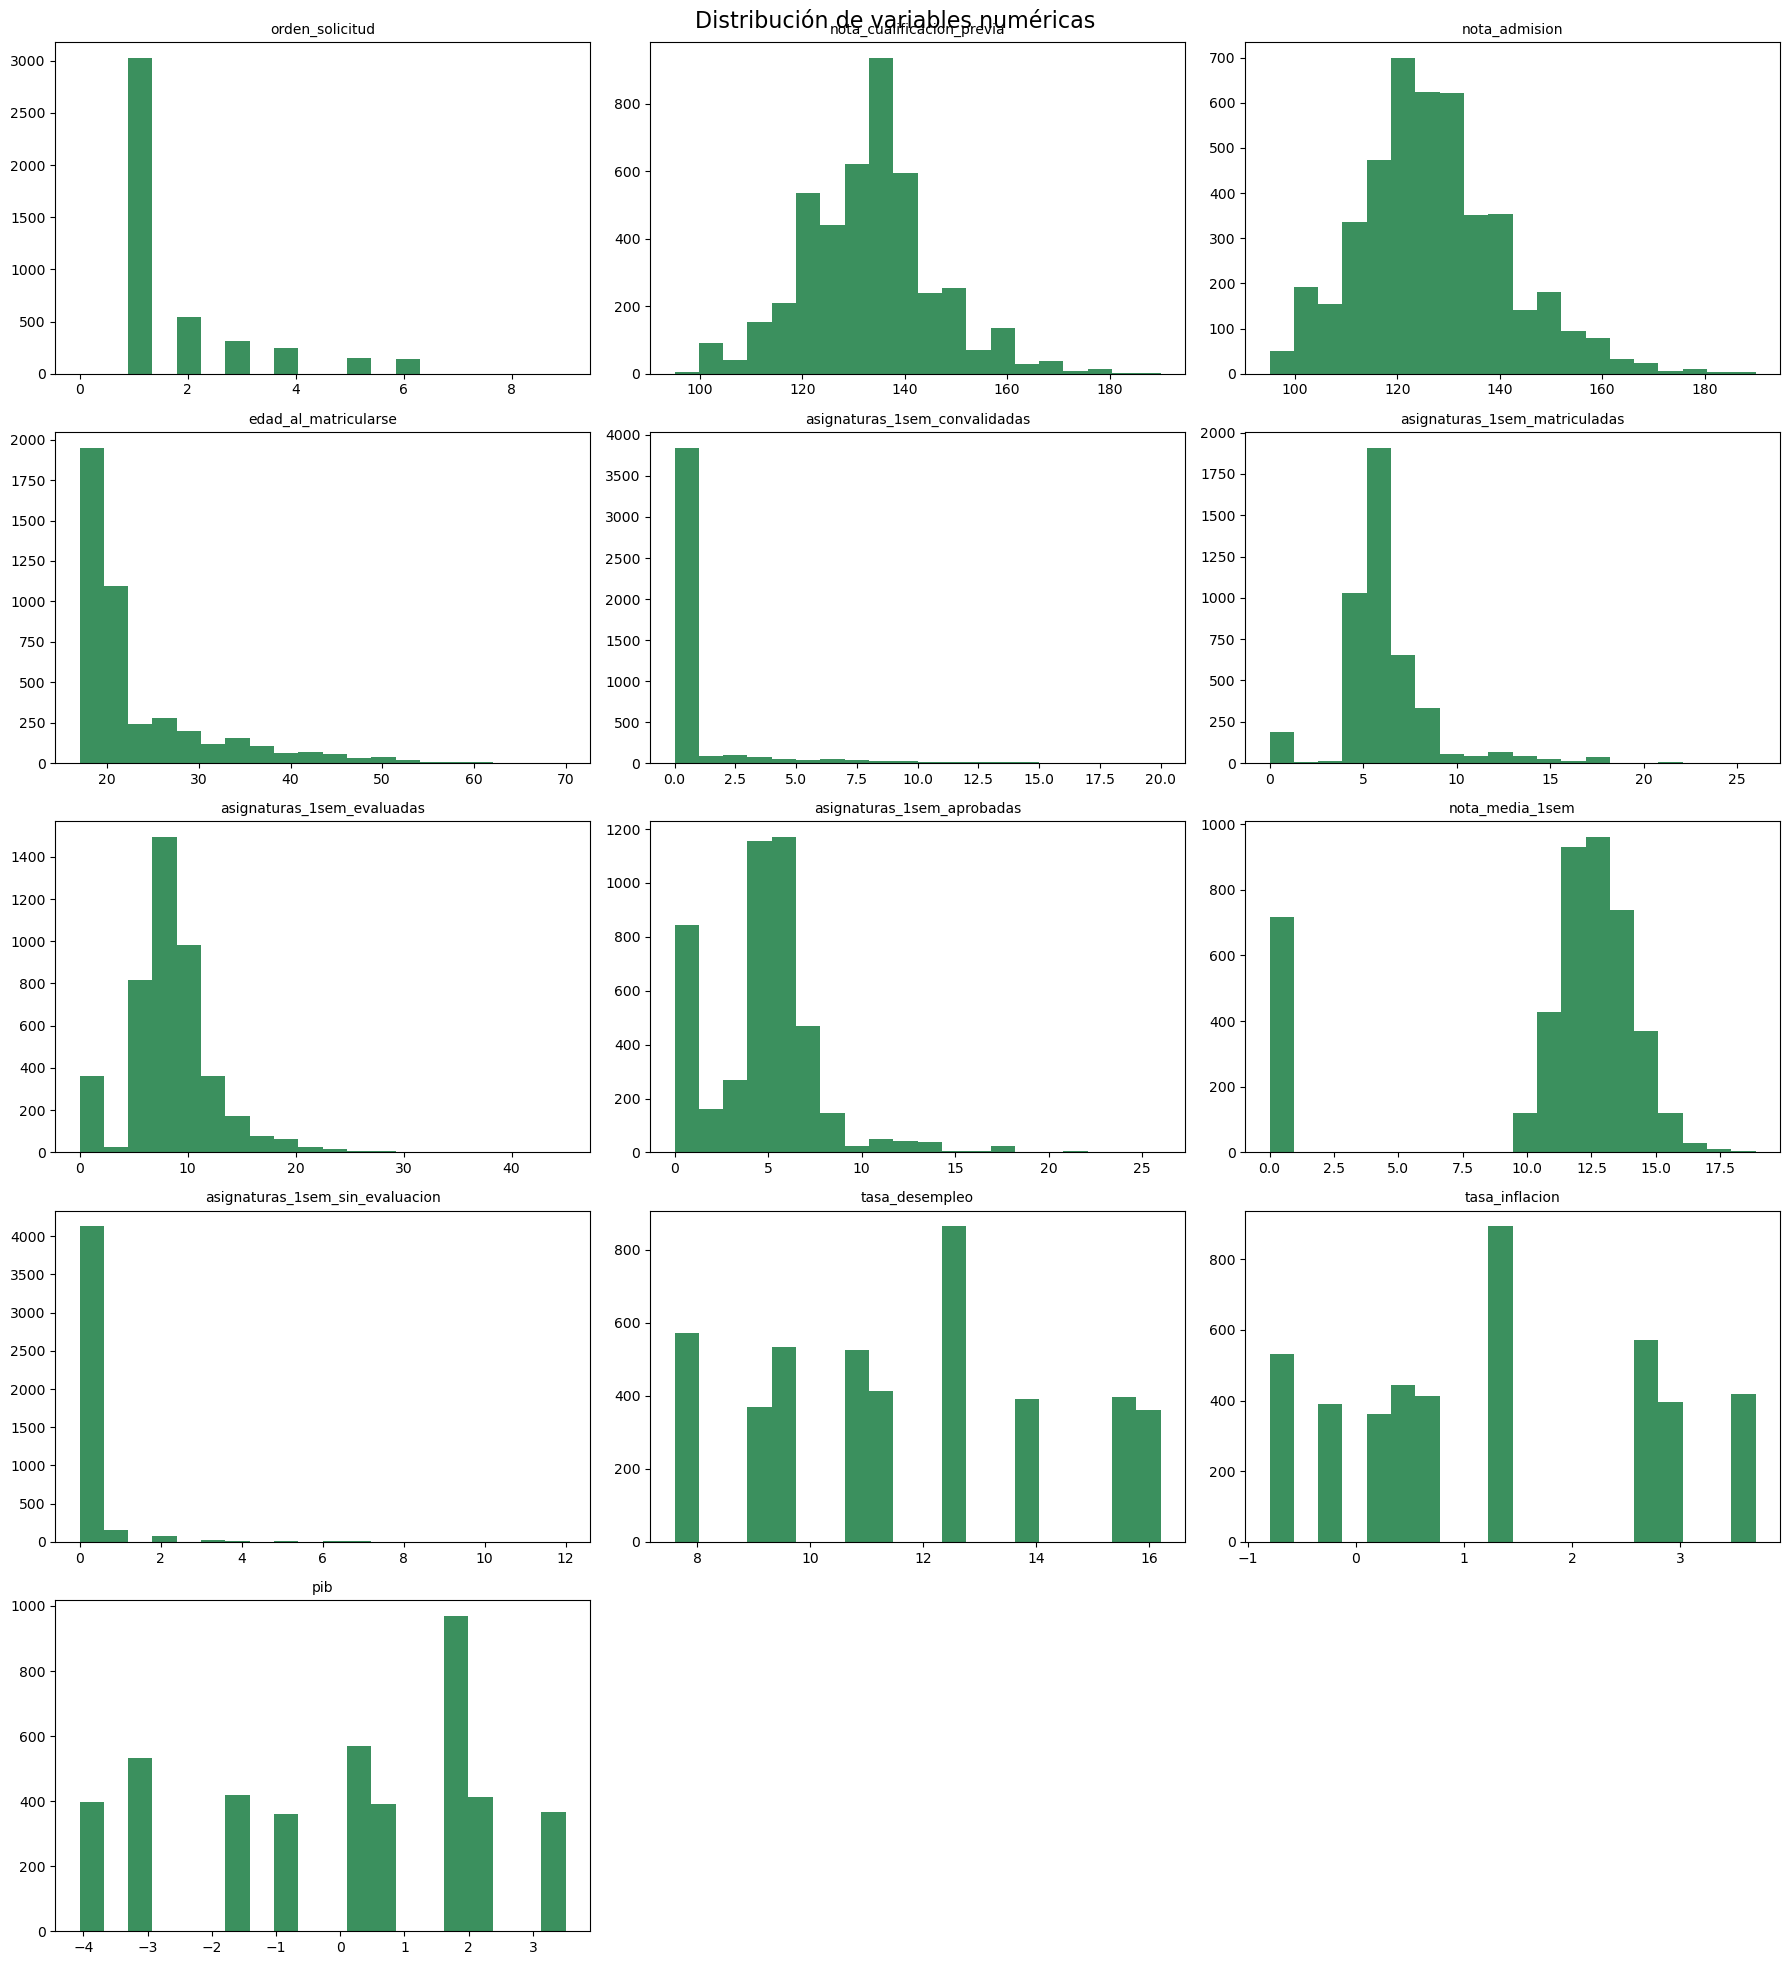

In [6]:
# Distribución variables numéricas

n_cols = 3
n_rows = math.ceil(len(col_num) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(col_num):
    axes[i].hist(df[col], bins=20, color="#3b905e")
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Distribución de variables numéricas", fontsize=16)
plt.tight_layout()
plt.show()

### 1.2. Exploración variable objetivo

La variable que se va a intentar predecir es nota_media_2sem. Veamos su distribución y cual es su relación con otras variables

Distribución de `nota_media_2sem`

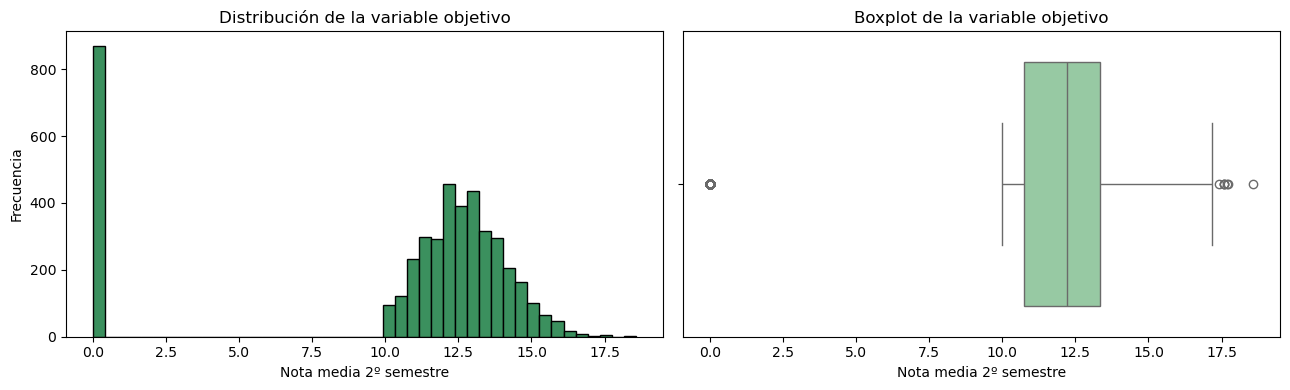

count    4424.000000
mean       10.230206
std         5.210808
min         0.000000
25%        10.750000
50%        12.200000
75%        13.333333
max        18.571429
Name: nota_media_2sem, dtype: float64

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(y, bins=45, edgecolor="black", color="#3b905e")
axes[0].set_title("Distribución de la variable objetivo")
axes[0].set_xlabel("Nota media 2º semestre")
axes[0].set_ylabel("Frecuencia")

sns.boxplot(x=y, ax=axes[1], color="#8fd19e")
axes[1].set_title("Boxplot de la variable objetivo")
axes[1].set_xlabel("Nota media 2º semestre")

plt.tight_layout()
plt.show()

y.describe()

Se observa que la variable objetivo tiene una distribución asimétrica, pues como se ven en las gráficas, hay un dos concentraciones de datos: en el valor de 0 y otro entre los valores de 10 y 14. Esto nos sugiere que hay estudiantes con un rendimiento académico "normal" mientras que hay otro grupo de alumnos que probablemente hayan abandonado los estudios.

Distribución de `nota_media_2sem` sin los valores de 0

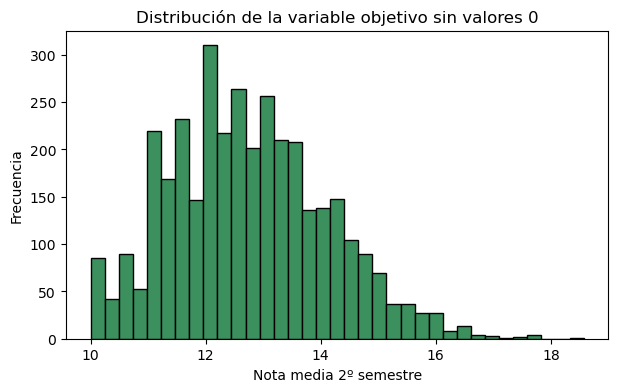

In [8]:
plt.figure(figsize=(7,4))
plt.hist(y[y > 0], bins=35, edgecolor="black", color="#3b905e")
plt.title("Distribución de la variable objetivo sin valores 0")
plt.xlabel("Nota media 2º semestre")
plt.ylabel("Frecuencia")
plt.show()

## 2. Codificación de las variables categóricas y separación train/test

### 2.1. Comenzamos por dividir el set de datos en train y test

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=55)

col_cat = X_train.select_dtypes(include=["object", "category"]).columns.to_list()
col_num = X_train.select_dtypes(include=["int64", "float64"]).columns.to_list()

### 2.2. Funciones para el preprocesado de datos

In [10]:
def datos_fold(X_train, X_validation, col_num, col_cat, escalar=True, drop_first=True):

    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first")    

    X_train_num = X_train[col_num].copy()
    X_val_num = X_validation[col_num].copy()

    if escalar:
        scaler = StandardScaler()
        X_train_num = pd.DataFrame(scaler.fit_transform(X_train_num), columns=col_num, index=X_train.index)
        X_val_num = pd.DataFrame(scaler.transform(X_val_num), columns=col_num, index=X_validation.index)
    
    XCat_train = ohe.fit_transform(X_train[col_cat])
    XCat_val = ohe.transform(X_validation[col_cat])

    cat_names = ohe.get_feature_names_out(col_cat)

    XCat_train = pd.DataFrame(XCat_train, columns=cat_names, index=X_train.index)
    XCat_val = pd.DataFrame(XCat_val, columns=cat_names, index=X_validation.index)
    
    # Concatenar datasets
    X_train_lineal = pd.concat([X_train_num, XCat_train], axis=1)
    X_test_lineal = pd.concat([X_val_num, XCat_val], axis=1)

    return X_train_lineal, X_test_lineal

def evaluar_modelo(modelo_fit, X_train, y_train, cv, col_num, col_cat, escalar=True, drop_first=True):

    rmse = []
    mae = []
    r2 = []

    for train_idx, val_idx in cv.split(X_train):
        X_train_fold  = X_train.iloc[train_idx].copy()
        X_val_fold = X_train.iloc[val_idx].copy()
        y_train_fold = y_train.iloc[train_idx].copy()
        y_val_fold = y_train.iloc[val_idx].copy()

        X_tr_process, X_val_process = datos_fold(X_train_fold, X_val_fold, col_num, col_cat, escalar, drop_first)
        modelo=modelo_fit()
        modelo.fit(X_tr_process, y_train_fold)
        predictions = modelo.predict(X_val_process)

        rmse.append(np.sqrt(mean_squared_error(y_val_fold, predictions)))
        mae.append(mean_absolute_error(y_val_fold, predictions))
        r2.append(r2_score(y_val_fold, predictions))

    return {"rmse": np.mean(rmse),
        "rmse_std": np.std(rmse),
        "mae": np.mean(mae),
        "mae_std": np.std(mae),
        "R2": np.mean(r2),
        "R2_std": np.std(r2)}



In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=55)
for train_idx, val_idx in cv.split(X_train):
    print(X_train.iloc[train_idx])

     estado_civil               modo_solicitud  orden_solicitud  \
3114   sin_pareja  1a_fase_contingente_general                1   
4090   con_pareja             mayor_de_23_anos                1   
3723   sin_pareja  2a_fase_contingente_general                2   
1355   sin_pareja  1a_fase_contingente_general                1   
3295   sin_pareja  2a_fase_contingente_general                2   
...           ...                          ...              ...   
673    sin_pareja  1a_fase_contingente_general                2   
3419   sin_pareja  2a_fase_contingente_general                1   
2021   sin_pareja             mayor_de_23_anos                1   
968    con_pareja             mayor_de_23_anos                1   
4391   con_pareja                    titulados                1   

                          curso asistencia_diurna_vespertina  \
3114  periodismo_y_comunicacion                       diurna   
4090   servicio_social_nocturno                   vespertina   
372

### 2.2. Escalado y codificación para los modelos lineales

Para codificar las variables categóricas utilizo one-hot encoding, usando `drop="first` evitando multicolinealidad perfecta entre variables dummy y estabilizar la regresión lineal

In [12]:
scaler = StandardScaler()
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first")    

Para los modelos lineales: he de escalar las variables numéricas y codificar las categóricas

In [13]:
X_cat_train = X_train[col_cat].copy()
X_num_train = X_train[col_num].copy()

X_cat_test = X_test[col_cat].copy()
X_num_test = X_test[col_num].copy()


# Escalado numérico
XNum_train = scaler.fit_transform(X_num_train)
XNum_test = scaler.transform(X_num_test)

XNum_train = pd.DataFrame(XNum_train, columns=col_num, index=X_train.index)
XNum_test = pd.DataFrame(XNum_test, columns=col_num, index=X_test.index)

# One-hot encoding
XCat_train = ohe.fit_transform(X_cat_train)
XCat_test = ohe.transform(X_cat_test)

cat_names = ohe.get_feature_names_out(col_cat)

XCat_train = pd.DataFrame(XCat_train, columns=cat_names, index=X_train.index)
XCat_test = pd.DataFrame(XCat_test, columns=cat_names, index=X_test.index)


# Concatenar datasets
X_train_lineal = pd.concat([XNum_train, XCat_train], axis=1)
X_test_lineal = pd.concat([XNum_test, XCat_test], axis=1)



c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


### 2.3. Codificación para RandomForest

Para Random Forest, no he de escalar los datos, sólo hacer encoding

In [14]:
ohe2 = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

In [15]:
# One hot encoding
X_cat_train_rf = X_train[col_cat].copy()
X_num_train_rf = X_train[col_num].copy()

X_cat_test_rf = X_test[col_cat].copy()
X_num_test_rf = X_test[col_num].copy()

XCat_train_rf = ohe2.fit_transform(X_cat_train_rf)
XCat_test_rf = ohe2.transform(X_cat_test_rf)

cat_names_rf = ohe2.get_feature_names_out(col_cat)

XCat_train_rf = pd.DataFrame(XCat_train_rf, columns=cat_names_rf, index=X_train.index)
XCat_test_rf = pd.DataFrame(XCat_test_rf, columns=cat_names_rf, index=X_test.index)

X_train_rf = pd.concat([X_num_train_rf, XCat_train_rf], axis=1)
X_test_rf = pd.concat([X_num_test_rf, XCat_test_rf], axis=1)

##  3. Creación de un modelo base

Comienzo por crear un modelo base para poder tener un punto de referencia donde comparar después Lasso, ElasticNet y Random Forest regressor. Para ello utilizo regresión lineal sin regularización.

In [16]:
metricas ={}

In [17]:
Regresion_lineal = LinearRegression()
Regresion_lineal.fit(X_train_lineal, y_train)
pred_rl = Regresion_lineal.predict(X_test_lineal)

rmse_lr = np.sqrt(mean_squared_error(y_test, pred_rl))
mae_lr = mean_absolute_error(y_test, pred_rl)
r2_lr = r2_score(y_test, pred_rl)

metricas["Regresion_lineal"] = {"rmse": rmse_lr, "mae":mae_lr, "R2":r2_lr}

print("RMSE:", rmse_lr)
print("MAE:", mae_lr)
print("R2:", r2_lr) 

RMSE: 2.758953230109525
MAE: 1.6306178503828814
R2: 0.724417754615753


## 4. Ajuste de los hiperparámetros

In [18]:
cv = KFold(n_splits=5, shuffle=True, random_state=55)

### 4.1. Hiperparámetros para Lasso

In [19]:
resultados = []

alphas = [0.001, 0.01, 0.1, 1, 10]

for a in alphas:

    metricas_cv = evaluar_modelo(
        lambda a=a: Lasso(alpha=a),
        X_train, y_train, cv, col_num, col_cat,
        escalar=True, drop_first=True
    )

    resultados.append({
        "alpha": a,
        "rmse": metricas_cv["rmse"],
        "rmse_std": metricas_cv["rmse_std"],
        "mae": metricas_cv["mae"],
        "mae_std": metricas_cv["mae_std"],
        "R2": metricas_cv["R2"],
        "R2_std": metricas_cv["R2_std"]
    })

resultados_df = pd.DataFrame(resultados).sort_values(by="rmse", ascending=True)
alpha_lasso = resultados_df.iloc[0]["alpha"]
print(resultados_df)

c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unk

    alpha      rmse  rmse_std       mae   mae_std        R2    R2_std
1   0.010  2.556464  0.133955  1.442690  0.082379  0.756989  0.029409
0   0.001  2.565254  0.126095  1.490713  0.077260  0.755467  0.027483
2   0.100  2.635717  0.150099  1.446348  0.089310  0.741508  0.033895
3   1.000  2.916455  0.116780  1.894786  0.047366  0.684170  0.030296
4  10.000  5.199109  0.056296  4.014548  0.061164 -0.000706  0.000653


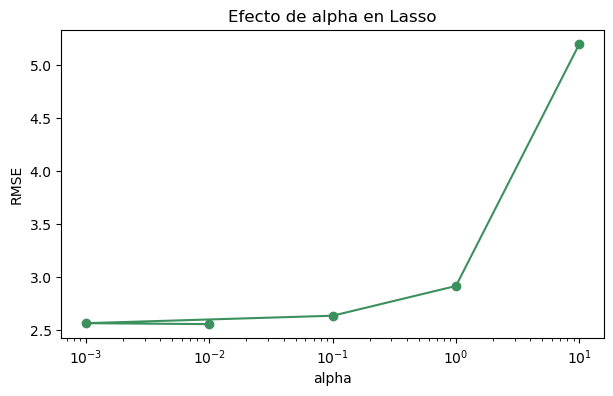

Mejor alpha Lasso: 0.01


In [20]:
plt.figure(figsize=(7,4))
plt.plot(resultados_df["alpha"], resultados_df["rmse"], marker="o", color="#3b905e")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("RMSE")
plt.title("Efecto de alpha en Lasso")
plt.show()

print("Mejor alpha Lasso:", alpha_lasso)

### 4.2. Hiperparámetros para ElasticNet

In [21]:
resultados = []

alphas = [0.001, 0.01, 0.1, 1, 10]

l1_ratios = [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]

for a in alphas:
    for l1 in l1_ratios:
        
        metricas_cv = evaluar_modelo(
        lambda a=a, l1=l1: ElasticNet(alpha=a, l1_ratio=l1, max_iter=10000),
        X_train, y_train, cv, col_num, col_cat,
        escalar=True, drop_first=True
    )

        resultados.append({
            "alpha": a,
            "l1_ratio":l1,
            "rmse": metricas_cv["rmse"],
            "rmse_std": metricas_cv["rmse_std"],
            "mae": metricas_cv["mae"],
            "mae_std": metricas_cv["mae_std"],
            "R2": metricas_cv["R2"],
            "R2_std": metricas_cv["R2_std"]
    })


resultados_df = pd.DataFrame(resultados).sort_values(by="rmse", ascending=True)
alpha_elastic = resultados_df.iloc[0]["alpha"]
l1_elastic = resultados_df.iloc[0]["l1_ratio"]
print(f"El hiperparámetro alpha para el modelo escogido es: {alpha_elastic} y el valor de l1: {l1_elastic}")

c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unk

El hiperparámetro alpha para el modelo escogido es: 0.01 y el valor de l1: 0.5


c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


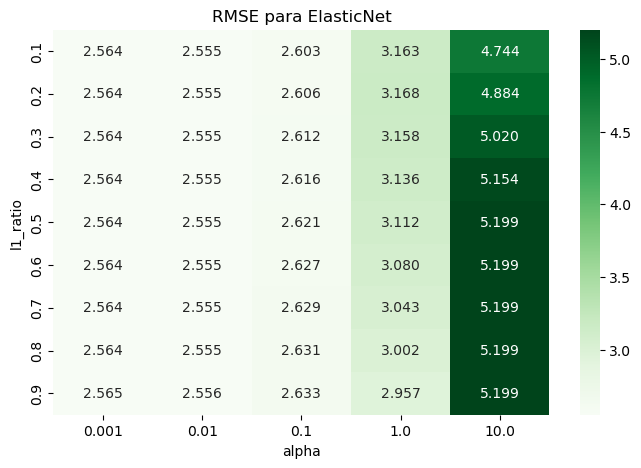

Mejor alpha ElasticNet: 0.01
Mejor l1_ratio ElasticNet: 0.5


In [22]:
tabla_rmse_elastic = resultados_df.pivot(index="l1_ratio", columns="alpha", values="rmse")

plt.figure(figsize=(8,5))
sns.heatmap(tabla_rmse_elastic, annot=True, fmt=".3f", cmap="Greens")
plt.title("RMSE para ElasticNet")
plt.xlabel("alpha")
plt.ylabel("l1_ratio")
plt.show()

alpha_elastic = resultados_df.iloc[0]["alpha"]
l1_elastic = resultados_df.iloc[0]["l1_ratio"]

print("Mejor alpha ElasticNet:", alpha_elastic)
print("Mejor l1_ratio ElasticNet:", l1_elastic)

### 4.3. Hiperparámetros para Random Forest Regressor

In [23]:
resultados = []

n_estimadores = [100,200,300]
max_depth = [10,20,30]
min_leaf = [1,2,4]

for n in n_estimadores:
    for prof in max_depth:
        for min_l in min_leaf:
            metricas_cv = evaluar_modelo(
                lambda n=n, prof=prof, min_l=min_l: RandomForestRegressor(
                    n_estimators=n,
                    max_depth=prof,
                    min_samples_leaf=min_l,
                    random_state=55,
                    n_jobs=-1
                ),
                X_train, y_train, cv, col_num, col_cat,
                escalar=False, drop_first=False
            )

            resultados.append({
                "n_estimator": n,
                "max_depth": prof,
                "min_leaf": min_l,
                "rmse": metricas_cv["rmse"],
                "rmse_std": metricas_cv["rmse_std"],
                "mae": metricas_cv["mae"],
                "mae_std": metricas_cv["mae_std"],
                "R2": metricas_cv["R2"],
                "R2_std": metricas_cv["R2_std"]
            })

resultados_df = pd.DataFrame(resultados).sort_values(by="rmse", ascending=True)
depth_rf = int(resultados_df.iloc[0]["max_depth"])
estimators_rf = int(resultados_df.iloc[0]["n_estimator"])
leafs_rf = int(resultados_df.iloc[0]["min_leaf"])
print(resultados_df)

print("Mejor n_estimators:", estimators_rf)
print("Mejor max_depth:", depth_rf)
print("Mejor min_samples_leaf:", leafs_rf)


c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\maivi\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unk

    n_estimator  max_depth  min_leaf      rmse  rmse_std       mae   mae_std  \
20          300         10         4  2.471179  0.131392  1.268637  0.063211   
23          300         20         4  2.472137  0.131429  1.271014  0.066206   
26          300         30         4  2.472178  0.131490  1.271101  0.066270   
11          200         10         4  2.472695  0.134009  1.269311  0.064383   
17          200         30         4  2.473702  0.134211  1.272610  0.067311   
14          200         20         4  2.473707  0.134140  1.272567  0.067246   
2           100         10         4  2.475064  0.126389  1.271749  0.064647   
8           100         30         4  2.477102  0.127915  1.275665  0.068290   
5           100         20         4  2.477140  0.127829  1.275543  0.068050   
19          300         10         2  2.485882  0.129308  1.277404  0.061328   
10          200         10         2  2.486710  0.127494  1.279106  0.060431   
1           100         10         2  2.

## 5. Creación de los modelos

### 5.1. Lasso

In [40]:
Modelo_Lasso = Lasso(alpha=alpha_lasso)
Modelo_Lasso.fit(X_train_lineal, y_train)
pred_lasso = Modelo_Lasso.predict(X_test_lineal)

rmse_lasso = np.sqrt(mean_squared_error(y_test, pred_lasso))
mae_lasso = mean_absolute_error(y_test, pred_lasso)
r2_lasso = r2_score(y_test, pred_lasso)

metricas["Lasso"] = {"rmse": rmse_lasso, "mae":mae_lasso, "R2":r2_lasso, 
                     "modelo": Modelo_Lasso, "predicciones": pred_lasso}

print("RMSE:", rmse_lasso)
print("MAE:", mae_lasso)
print("R2:", r2_lasso) 

RMSE: 2.766672604462799
MAE: 1.5788702109633868
R2: 0.7228734743068055


### 5.2. ElasticNet

In [41]:
Elastic_Net = ElasticNet(alpha=alpha_elastic, l1_ratio = l1_elastic)
Elastic_Net.fit(X_train_lineal, y_train)
pred_EN = Elastic_Net.predict(X_test_lineal)

rmse_EN = np.sqrt(mean_squared_error(y_test, pred_EN))
mae_EN= mean_absolute_error(y_test, pred_EN)
r2_EN = r2_score(y_test, pred_EN)

metricas["ElasticNet"] = {"rmse": rmse_EN, "mae":mae_EN, "R2":r2_EN, 
                          "modelo":Elastic_Net, "predicciones": pred_EN}

print("RMSE:", rmse_EN)
print("MAE:", mae_EN)
print("R2:", r2_EN) 


RMSE: 2.7606775588095163
MAE: 1.5855222433615808
R2: 0.7240731725717309


### 5.4. Random Forest Regressor

In [42]:
RF = RandomForestRegressor(max_depth=depth_rf, min_samples_leaf=leafs_rf, n_estimators=estimators_rf)
RF.fit(X_train_rf, y_train)
pred_RF = RF.predict(X_test_rf)

rmse_RF = np.sqrt(mean_squared_error(y_test, pred_RF))
mae_RF = mean_absolute_error(y_test, pred_RF)
r2_RF = r2_score(y_test, pred_RF)

metricas["RandomForestRegressor"] = {"rmse": rmse_RF, "mae":mae_RF, "R2":r2_RF, 
                                     "modelo": RF, "predicciones": pred_RF}

print("RMSE:", rmse_RF)
print("MAE:", mae_RF)
print("R2:", r2_RF) 

RMSE: 2.615566377420929
MAE: 1.3694064119846683
R2: 0.7523182260391054


## 6. Evaluación de los modelos

Una vez creados los modelos, comparamos los resultados obtenidos de los modelos a través de las métricas calculadas

In [43]:
resultados_modelos = pd.DataFrame(metricas)
print(resultados_modelos.head(3))

      Regresion_lineal     Lasso ElasticNet RandomForestRegressor
rmse          2.758953  2.766673   2.760678              2.615566
mae           1.630618   1.57887   1.585522              1.369406
R2            0.724418  0.722873   0.724073              0.752318


A partir de los resultados que hemos obtenido se puede ver que el mejor modelo es Random Forest Regressor pues presenta el mejor rendimiento global con los valores más bajos de RMSE y MAE. Además, su coeficiente de determinación (R2) es aproximadamente 0.75 lo que significa que explica la variabilidad de los datos casi en un 75%, asimismo, indica que el modelo muestra un mejor ajuste de lso datos.    

Por otro lado, los modelos lineales muestran un rendimiento bastante parecido entre ellos. El peor de los tres es el modelo sin regularización lo que indica que la regularización ayuda a mejorar el modelo y reducir ligeramente el error aunque no haya mucha diferencia.

El hecho de que Random Forest sea un mejor modelo se puede explicar por la capacidad que tiene de capturar relaciones no lineales y posibles interacciones entre las variables, al contrario que el resto de los modelos.   
Sin embargo, las diferencias entre los distintos modelos no son muy grandes lo que puede ser un indicativo de que una gran parte de la variabilidad de la variable objetivo puede ser explicada mediante las relaciones lineales.   

En conclusión tenemos que Random Forest Regressor es el mejor modelo de los probados pues aunque sea el que presenta una mayor complejidad que los modelos lineales presenta una mejor capacidad predictiva con respecto al resto.

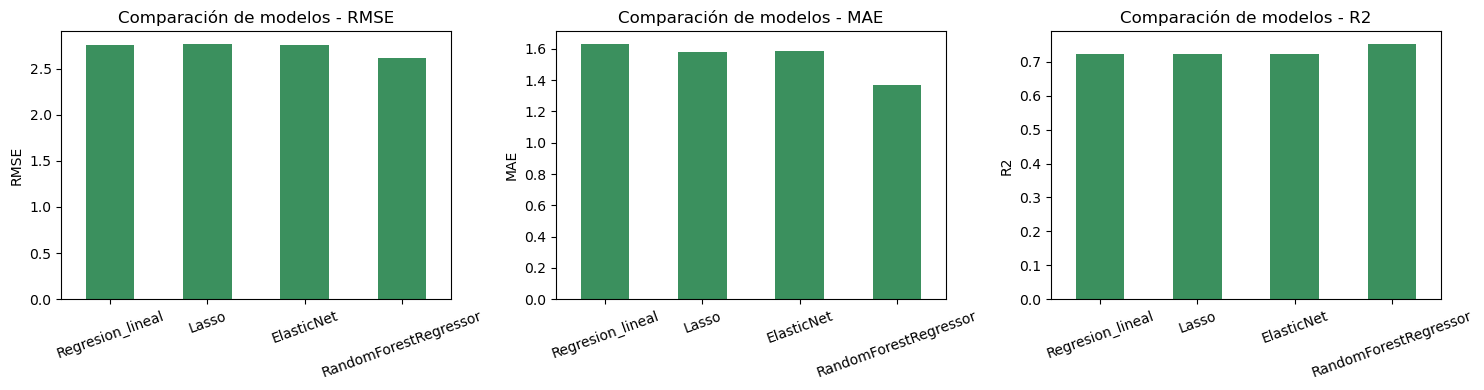

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

resultados_modelos.loc["rmse"].plot(kind="bar", ax=axes[0], color="#3b905e")
axes[0].set_title("Comparación de modelos - RMSE")
axes[0].set_ylabel("RMSE")
axes[0].tick_params(axis='x', rotation=20)

resultados_modelos.loc["mae"].plot(kind="bar", ax=axes[1], color="#3b905e")
axes[1].set_title("Comparación de modelos - MAE")
axes[1].set_ylabel("MAE")
axes[1].tick_params(axis='x', rotation=20)

resultados_modelos.loc["R2"].plot(kind="bar", ax=axes[2], color="#3b905e")
axes[2].set_title("Comparación de modelos - R2")
axes[2].set_ylabel("R2")
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

## 7. Modelo final

In [46]:
seleccion_modelos = resultados_modelos.T.sort_values("rmse")

nombre = seleccion_modelos.index[0]
modelo_final = seleccion_modelos.iloc[0]["modelo"]
pred_final = seleccion_modelos.iloc[0]["predicciones"]

rmse_final = np.sqrt(mean_squared_error(y_test, pred_final))
mae_final = mean_absolute_error(y_test, pred_final)
r2_final = r2_score(y_test, pred_final)

print("Modelo final:", nombre)
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_final)))
print("MAE:", mean_absolute_error(y_test, pred_final))
print("R2:", r2_score(y_test, pred_final))


Modelo final: RandomForestRegressor
RMSE: 2.615566377420929
MAE: 1.3694064119846683
R2: 0.7523182260391054


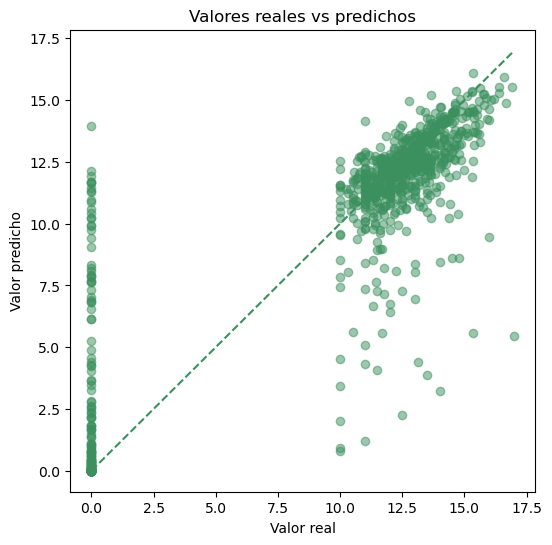

In [47]:
# Valores reales contra predichos:

plt.figure(figsize=(6,6))
plt.scatter(y_test, pred_final, alpha=0.5, color="#3b905e")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle="--", color="#3b905e")
plt.xlabel("Valor real")
plt.ylabel("Valor predicho")
plt.title("Valores reales vs predichos")
plt.show()

En el gráfico podemos observar que los valores que se encuentran cercanos a la media de las calificaciones reales son predichos de forma más correcta mientras que aquellos que se encuentran en el 0 son predicho de forma menos correcta.

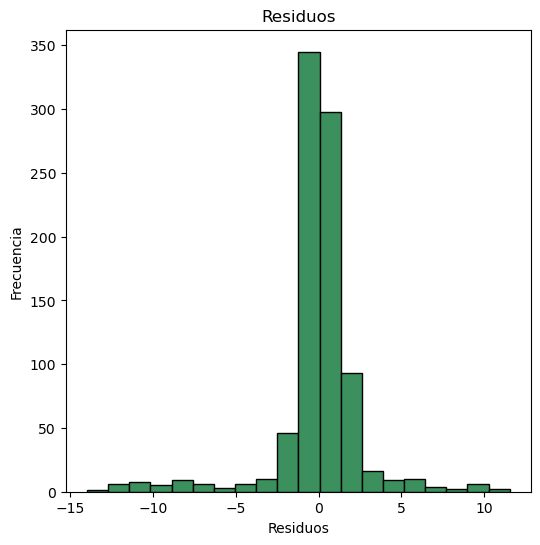

In [48]:
# Residuos

plt.figure(figsize=(6,6))
plt.hist(y_test - pred_final, bins=20, edgecolor="black", color="#3b905e")
plt.xlabel("Residuos")
plt.ylabel("Frecuencia")
plt.title("Residuos")
plt.show()

Para complementar el gráfico del histograma de lso residuos procedo a comparar la relación entre los residuos y la predicción para poder observar en que casos se confunde más el modelo


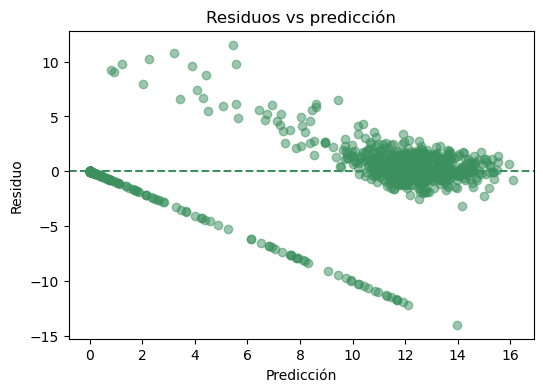

In [49]:
plt.figure(figsize=(6,4))
plt.scatter(pred_final, y_test - pred_final, alpha=0.5, color="#3b905e")
plt.axhline(0, linestyle="--", color="#3b905e")
plt.xlabel("Predicción")
plt.ylabel("Residuo")
plt.title("Residuos vs predicción")
plt.show()

En el histograma se observa que la mayor parte de los residuos se concentran en torno a 0, indicando que el modelo no presenta un sesgo significativo y realiza predicciones más o menos precisas para la mayoría de los casos.  
    
Sin embargo, la distribución presenta colas largas sobretodo en los valores negativos, mostrando errores grandes en algunos casos.  
En el siguiente gráfico, donde comparamos residuos contra predicciones, se confirma wl comportamiento que hemos predicho. En concreto, se puede observar, una estructura clara con líneas descendientes lo que indica que el error que se produce no es completamente aleatorio y depende del valor predicho.   

En conjunto, aunque el modelo presenta un buen rendimiento general, el análisis de residuos muestra limitaciones importantes en la predicción de ciertos grupos de datos, especialmente aquellos con valores extremos o atípicos, reflejando la complejidad del problema.

Con estas conclusiones procedemos a estudiar si el error cambia según cambia el rango de la nota.

In [50]:
evaluaciones = pd.DataFrame({"real":y_test, "pred":pred_final})

evaluaciones["error_abs"] = abs(evaluaciones["real"]- evaluaciones["pred"])
evaluaciones["tramo"] = pd.cut(evaluaciones["real"], bins=[-0.1,0.1,5,10,15,20])

evaluaciones.groupby("tramo")["error_abs"].mean()

C:\Users\maivi\AppData\Local\Temp\ipykernel_34796\3969724636.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  evaluaciones.groupby("tramo")["error_abs"].mean()


tramo
(-0.1, 0.1]     2.524695
(0.1, 5.0]           NaN
(5.0, 10.0]     2.917635
(10.0, 15.0]    0.976281
(15.0, 20.0]    1.703920
Name: error_abs, dtype: float64

Con este nuevo análisis se puede observar que el comportamiento del modelo no es homogéneo en todos los rangos, en concreto vemos que el error medio es mayor en los valores más bajos, especialmente en el intervalo correspondiente a valores cercanos a 0 indicando que el modelo tiene más dificultades para predecir correctamente estos casos.    
Por otro lado, se observa que en el rango intermedio (10-15) el error baja notablemente, confirmando que el modelo presenta un mejor rendimiento en los valores más representativos de las distribución.    
En los valores más altos, los comprendidos entre 15  y 20, el error vuelve a subir auqnue no de forma tan brusca como en el primer intervalo.

Estos resultados nos indican que el modelo es más preciso en los rangos de valores donde se centran la mayor parte de los datos, mientras que en los extremos predice con mayor dificultad, especialmente en los valores cercanos a 0.

## 8. Importancia de las variables 

In [51]:
# Cojo el feature importance y me quedo con las 20 variables más importante
featureImportance= pd.DataFrame({'Feature Importance':modelo_final.feature_importances_*100}, index= X_train_rf.columns)
featureImportance=featureImportance.sort_values('Feature Importance', ascending=False).head(20)

featureImportance.head(20)

,Feature Importance
asignaturas_1sem_aprobadas,80.052632
nota_media_1sem,6.578156
asignaturas_1sem_evaluadas,1.629473
nota_admision,1.436098
edad_al_matricularse,1.245963
nota_cualificacion_previa,1.109245
tasa_desempleo,0.922782
tasa_inflacion,0.726557
asignaturas_1sem_matriculadas,0.668220
pib,0.663956


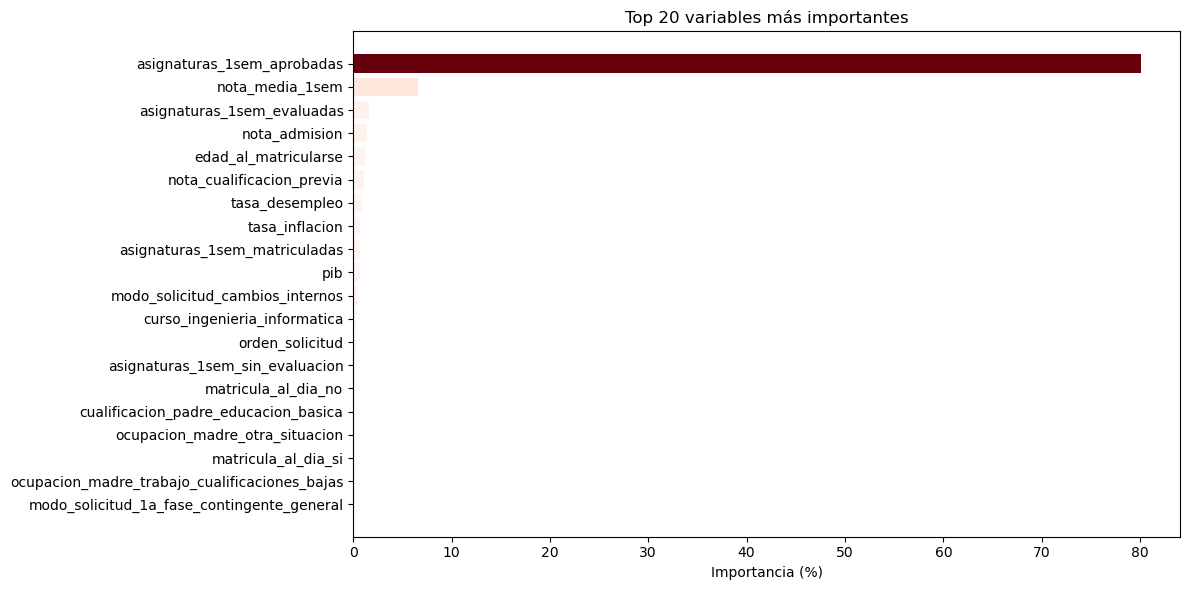

In [52]:
# Normalizo los valores y se elige el color del mapa
valores = featureImportance["Feature Importance"]
norm = plt.Normalize(valores.min(), valores.max())
colores = plt.cm.Reds(norm(valores))

# Graficamos
plt.figure(figsize=(12,6))
plt.barh(featureImportance.index[::-1], valores[::-1], color=colores[::-1])
plt.xlabel('Importancia (%)')
plt.title('Top 20 variables más importantes')
plt.tight_layout()
plt.show()

Viendo la importancia de las variables se puede observar que los resultados del primer semestre tiene un gran impacto sobre la predicción de la nota media del segundo semestre

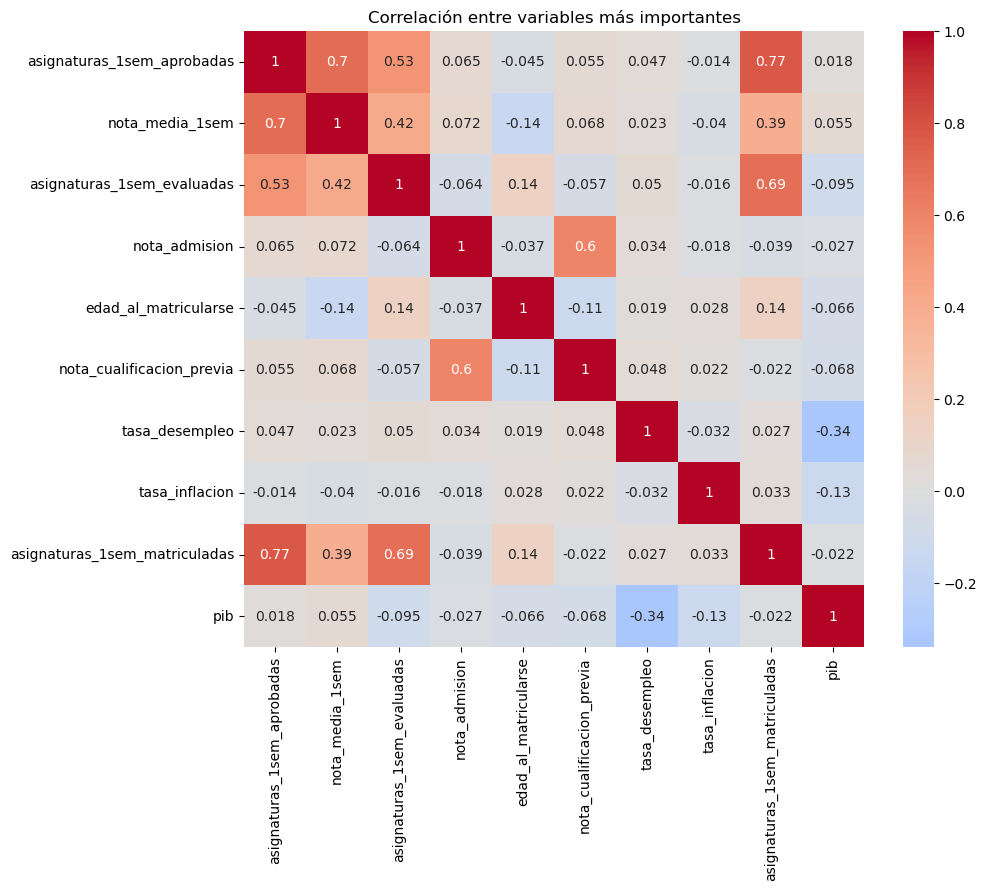

In [53]:
top_vars = featureImportance.head(10).index.tolist()

plt.figure(figsize=(10,8))
sns.heatmap(X_train_rf[top_vars].corr(numeric_only=True), annot=True, cmap="coolwarm", center=0)
plt.title("Correlación entre variables más importantes")
plt.show()

En este gráfico podemos observar que las correlaciones entre las variables más importantes no son tan altas, lo que significa que no se podría eliminar ninguna variable con el fin de bajar dimensionalidad y crear un mejor modelo